# Music Hits

Predict which tracks are music hits, based on metadata and audio features. Evaluation metric is Roc Auc Score.

Import the packages that will be used:

In [1]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import roc_auc_score

Download the competition dataset:

In [2]:
path = kagglehub.competition_download('music-hits-2026')

path

100%|██████████| 23.7M/23.7M [00:36<00:00, 678kB/s] 

Extracting files...


'C:\\Users\\ricky\\.cache\\kagglehub\\competitions\\music-hits-2026'

# Training data

Read the training data from a CSV file, using the *id* column as index:

In [3]:
df = pd.read_csv(os.path.join(path, 'train.csv'), index_col='id')

df

,track_name,album_type,album_name,release_date,record_label,duration_sec,audio_dance,audio_energy,audio_key,audio_loudness,...,audio_instrumental,audio_live,audio_valence,audio_tempo,time_signature,artist_name,artist_genres,artist_followers,explicit_lyrics,music_hit
id,,,,,,,,,,,,,,,,,,,,,
1,Alphabet Song,album,"Animals, Vol.1",1956-01-01,Folkways Records,55.053,0.752,0.1820,0,-17.907,...,0.06570,0.1040,0.936,164.686,4,Alan Mills,NaN,1404,False,0
2,One More River,album,"Animals, Vol.1",1956-01-01,Folkways Records,124.666,0.873,0.2010,6,-14.813,...,0.32300,0.1280,0.863,124.988,4,Alan Mills,NaN,1404,False,0
3,Mistress Bond,album,"Animals, Vol.1",1956-01-01,Folkways Records,102.480,0.885,0.0935,9,-17.956,...,0.00848,0.1180,0.843,111.172,4,Alan Mills,NaN,1404,False,0
4,Who Killed Cock Robin?,album,"Animals, Vol.1",1956-01-01,Folkways Records,188.906,0.447,0.0451,0,-21.767,...,0.51400,0.1140,0.325,89.249,4,Alan Mills,NaN,1404,False,0
5,The Bird'S Ball,album,"Animals, Vol.1",1956-01-01,Folkways Records,106.466,0.781,0.1890,9,-15.477,...,0.48700,0.1190,0.961,107.608,4,Alan Mills,NaN,1404,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
350047,Symphony No. 17 In G Major K. 129: 2. Andante,album,"Mozart: Symphony No.31 ""Paris"", No.23, No.16 &...",2023-12-20,EXTON,403.173,0.385,0.0234,0,-24.204,...,0.61600,0.2040,0.208,89.885,4,Wolfgang Amadeus Mozart,classical|classical era,5283190,False,0
350048,Symphony No. 17 In G Major K. 129: 3. Allegro,album,"Mozart: Symphony No.31 ""Paris"", No.23, No.16 &...",2023-12-20,EXTON,252.213,0.401,0.2370,7,-17.375,...,0.92600,0.1880,0.795,141.869,3,Wolfgang Amadeus Mozart,classical|classical era,5283190,False,0
350049,Two Of Hearts - Sped Up 2,single,Two Of Hearts (Sped Up 2),2023-12-20,Viral Tunes,195.865,0.614,0.5930,9,-10.251,...,0.00000,0.0938,0.695,163.974,4,skyemane,NaN,20784,False,0


Observe the data types of the columns:

In [4]:
df.dtypes.to_frame(name='dtype')

,dtype
track_name,str
album_type,str
album_name,str
release_date,str
record_label,str
duration_sec,float64
audio_dance,float64
audio_energy,float64
audio_key,int64
audio_loudness,float64


Check the number of missing values in each column:

In [5]:
df.isna().sum().to_frame(name='missing')

,missing
track_name,4
album_type,0
album_name,1
release_date,0
record_label,38
duration_sec,0
audio_dance,0
audio_energy,0
audio_key,0
audio_loudness,0


Check the distribution of the target variable:

In [6]:
df['music_hit'].value_counts().to_frame(name='count')

,count
music_hit,
0,313864
1,36187


# Feature selection

Select the numeric and Boolean features. The text, categorical and date columns are not used in this model:

In [7]:
target_column = 'music_hit'
feature_columns = df.select_dtypes(include=['number', 'bool']).columns.drop(target_column).tolist()
feature_columns

['duration_sec',
 'audio_dance',
 'audio_energy',
 'audio_key',
 'audio_loudness',
 'audio_mode',
 'audio_speech',
 'audio_acoustic',
 'audio_instrumental',
 'audio_live',
 'audio_valence',
 'audio_tempo',
 'time_signature',
 'artist_followers',
 'explicit_lyrics']

Confirm that the selected features have no missing values:

In [8]:
df[feature_columns].isna().sum().to_frame(name='missing')

,missing
duration_sec,0
audio_dance,0
audio_energy,0
audio_key,0
audio_loudness,0
audio_mode,0
audio_speech,0
audio_acoustic,0
audio_instrumental,0
audio_live,0


# Data splitting

Split the data into training and validation sets:

In [9]:
df_train, df_valid = train_test_split(
    df, test_size=0.2, random_state=0, stratify=df[target_column]
)
print(df_train.shape, df_valid.shape)

(280040, 23) (70011, 23)


Using *stratify* keeps approximately the same proportion of hits in both sets:

In [10]:
pd.concat([
    df_train[target_column].value_counts(normalize=True),
    df_valid[target_column].value_counts(normalize=True)
], axis=1, keys=['train', 'validation'])

,train,validation
music_hit,,
0,0.896622,0.896631
1,0.103378,0.103369


# Model fitting

Create a Decision Tree classifier:

In [11]:
model = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=0)

model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Fit the classifier to the training set:

In [12]:
model.fit(df_train[feature_columns], df_train[target_column])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Plot the fitted decision tree:

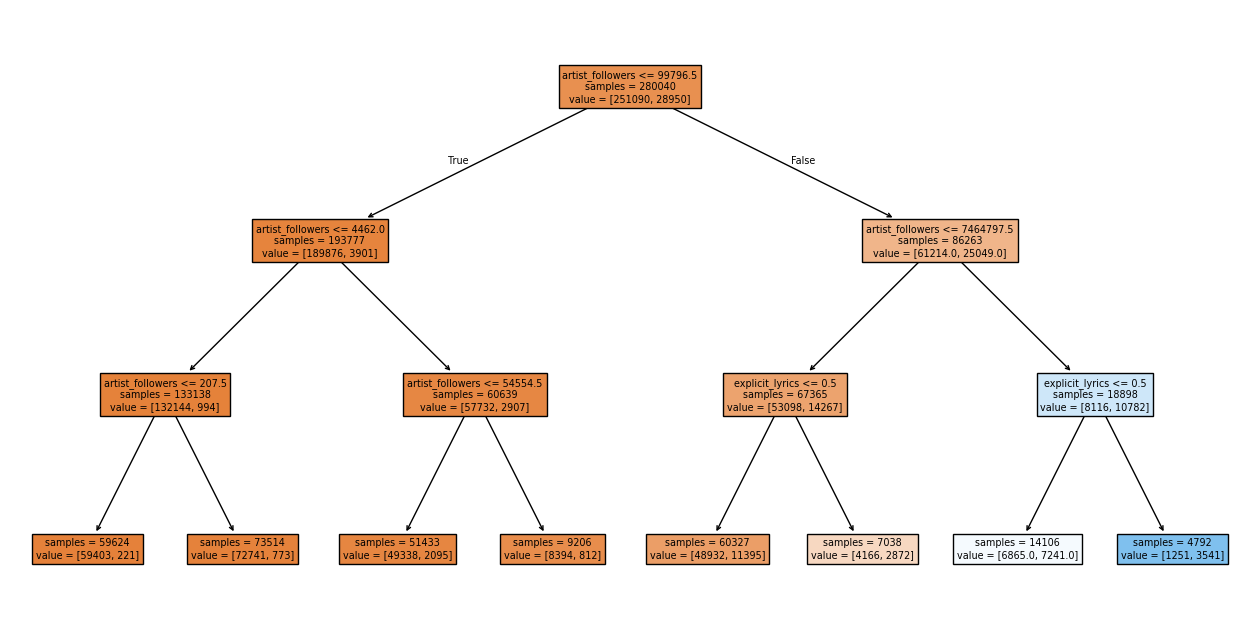

In [13]:
plt.figure(figsize=(16, 8))

plot_tree(model, feature_names=feature_columns, filled=True, impurity=False);

# Feature importance

Inspect the importance of each feature in the fitted tree:

In [14]:
feature_importances = pd.Series(model.feature_importances_, index=feature_columns)
feature_importances.sort_values(ascending=False).to_frame(name='importance')

,importance
artist_followers,0.959954
explicit_lyrics,0.040046
duration_sec,0.000000
audio_key,0.000000
audio_loudness,0.000000
audio_dance,0.000000
audio_energy,0.000000
audio_speech,0.000000
audio_mode,0.000000
audio_acoustic,0.000000


# Model evaluation

Predict the probability that each validation track is a hit:

In [ ]:
valid_probabilities = model.predict_proba(df_valid[feature_columns])[:, 1]
valid_probabilities[:10]

array([0.18888723, 0.18888723, 0.18888723, 0.00370656, 0.18888723,
       0.18888723, 0.010515  , 0.010515  , 0.18888723, 0.40807047])

Compute ROC AUC from the predicted probabilities:

In [16]:
auc = roc_auc_score(df_valid[target_column], valid_probabilities)
print(f'Validation ROC AUC: {auc:.4f}')

Validation ROC AUC: 0.8741


# Test data

Read the competition test data, using *id* as the index:

In [17]:
df_test = pd.read_csv(os.path.join(path, 'test.csv'), index_col='id')
df_test

,track_name,album_type,album_name,release_date,record_label,duration_sec,audio_dance,audio_energy,audio_key,audio_loudness,...,audio_acoustic,audio_instrumental,audio_live,audio_valence,audio_tempo,time_signature,artist_name,artist_genres,artist_followers,explicit_lyrics
id,,,,,,,,,,,,,,,,,,,,,
350052,The Barnyard Song,album,"Animals, Vol.1",1956-01-01,Folkways Records,113.186,0.825,0.188,2,-16.568,...,0.9350,0.005550,0.0998,0.7950,125.889,4,Alan Mills,NaN,1404,False
350053,It'S All Right With Me,album,Ella Fitzgerald Sings The Cole Porter Song Book,1956-01-01,Verve Reissues,188.840,0.395,0.267,0,-12.485,...,0.5120,0.000000,0.0433,0.7740,179.982,4,Ella Fitzgerald,adult standards|jazz|jazz blues|soul|swing|voc...,2398354,False
350054,It'S Delovely,album,Ella Fitzgerald Sings The Cole Porter Song Book,1956-01-01,Verve Reissues,164.120,0.601,0.285,0,-11.117,...,0.7480,0.000000,0.0468,0.4760,74.237,4,Ella Fitzgerald,adult standards|jazz|jazz blues|soul|swing|voc...,2398354,False
350055,Begin The Beguine,album,Ella Fitzgerald Sings The Cole Porter Song Book,1956-01-01,Verve Reissues,219.040,0.437,0.235,7,-12.089,...,0.6790,0.000000,0.0914,0.6480,126.051,4,Ella Fitzgerald,adult standards|jazz|jazz blues|soul|swing|voc...,2398354,False
350056,I'Ve Got You Under My Skin,album,Ella Fitzgerald Sings The Cole Porter Song Book,1956-01-01,Verve Reissues,163.333,0.626,0.100,7,-14.999,...,0.6750,0.000000,0.0852,0.6980,135.387,4,Ella Fitzgerald,adult standards|jazz|jazz blues|soul|swing|voc...,2398354,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
437560,O Santa Notte: Canzone Perfetta,album,2023 Ultimate Holiday Music,2023-12-17,T-Rel Music,331.000,0.328,0.141,7,-20.144,...,0.7120,0.000000,0.1020,0.3900,71.902,4,The Christmas Guys,christmas instrumental,2992,False
437561,2023 Christmas: Go Tell It On The Mountain,album,2023 Ultimate Holiday Music,2023-12-17,T-Rel Music,314.982,0.628,0.269,0,-16.590,...,0.8350,0.000221,0.3380,0.0376,106.024,4,The Christmas Guys,christmas instrumental,2992,False
437562,Symphony No.23 In D Major K.181(162B): 1. Alle...,album,"Mozart: Symphony No.31 ""Paris"", No.23, No.16 &...",2023-12-20,EXTON,304.573,0.354,0.191,2,-14.545,...,0.9030,0.924000,0.1940,0.3490,143.710,4,Wolfgang Amadeus Mozart,classical|classical era,5283190,False


Check that the selected features exist and have no missing values:

In [18]:
assert set(feature_columns).issubset(df_test.columns)
assert not df_test[feature_columns].isna().any().any()

# Test predictions

Fit the same model using all available labeled tracks:

In [19]:
model.fit(df[feature_columns], df[target_column])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Predict the probability of *music_hit = 1* for each track in the test set:

In [20]:
df_test[target_column] = model.predict_proba(df_test[feature_columns])[:, 1]
df_test[[target_column]]

,music_hit
id,
350052,0.010567
350053,0.188664
350054,0.188664
350055,0.188664
350056,0.188664
...,...
437560,0.010567
437561,0.010567
437562,0.188664


# Submission

Prepare the submission using the format and row order of *sample_submission.csv*:

In [21]:
df_submission = pd.read_csv(os.path.join(path, 'sample_submission.csv'))
assert df_submission.columns.tolist() == ['id', target_column]
assert df_submission['id'].tolist() == df_test.index.tolist()
df_submission[target_column] = df_test[target_column].to_numpy()
df_submission.head()

,id,music_hit
0,350052,0.010567
1,350053,0.188664
2,350054,0.188664
3,350055,0.188664
4,350056,0.188664


Save the submission file:

In [22]:
assert df_submission[target_column].between(0, 1).all()
df_submission.to_csv('submission.csv', index=False)
print(f'Saved {len(df_submission)} predictions to submission.csv')

Saved 87513 predictions to submission.csv
